# 04 高并发优化：Redis 合并写与延迟持久化


## 本章范围与资料来源

第 03 章已经实现学习记录、学习计划和进度统计。本章处理一个新的瓶颈：**前端每 15 秒提交一次播放进度，大量请求重复更新同一条记录，数据库承担了不必要的读写。**

学习路线：定位高频分支 → 选择合并写 → 设计 Redis Hash → 用 DelayQueue 检测停止提交 → 改造学习记录接口 → 补齐线程、事务和故障处理。

| 来源 | 本章使用的内容 |
| --- | --- |
| [网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj)，提取码 `w7bj` | `day04-高并发优化/讲义/day04-学习计划和进度的高并发优化.pptx`，共 48 页；重点是第 25–47 页 |
| [课程在线讲义：day04-高并发优化](https://my.feishu.cn/wiki/wikcnOj0nuqmVVS5XYqxBE8Lb1d) | 优化方案、DelayTask、LearningRecordDelayTaskHandler、LearningRecordServiceImpl、练习与面试问答 |
| 共享目录中的其他材料 | `资料`目录显示“没有数据”；存在 `提交学习记录.jmx`，这里只确认其文件名，未读取其配置或运行压测 |

PPT 的首页仍叫“学习计划和进度”，前 24 页延续上一章。这里按 day04 的教学内容整理。标注为**课件实现**的代码是已读讲义的关键片段或等价简化；**补充 / 改进示例**是为了说明实现边界增加的内容，不代表课程已经实现。


## 高并发优化的三个方向

请求变多时，单纯增加应用实例可能让数据库更快达到极限。先判断瓶颈在哪里，再决定优化方向。

| 方向 | 解决的问题 | 常用手段 | 边界 |
| --- | --- | --- | --- |
| 提高单机并发能力 | 一个实例处理请求太慢 | 优化代码、SQL、缓存、异步、合并写 | 本章重点；需要减少每次请求占用的资源 |
| 水平扩展 | 一个实例的容量不足 | 多实例、负载均衡 | 数据库、Redis、连接池等共享资源也要评估容量 |
| 服务保护 | 超负荷导致连锁故障 | 限流、熔断、降级 | 控制负载、隔离故障，不会凭空增加数据库吞吐量 |

**RT（Response Time，响应时间）**是请求从进入到返回的耗时；**QPS**是每秒请求数。在并发槽位和资源限制不变的理想情况下，缩短 RT 有利于提高吞吐量，但真实上限还受 CPU、网络、连接池和数据库锁竞争影响。

```text
用户请求 → 学习服务 → 查询旧记录 → 更新记录 → 更新课表 → 返回
                        ↑ 多次数据库交互拉长 RT
```


## 读优化与写优化

读缓存容易理解：查到相同的数据，就复用缓存结果。写优化则必须先问：**每次写入是否都需要保留？**

| 业务类型 | 优化手段 | 示例 |
| --- | --- | --- |
| 读多写少 | 优化查询、索引、批量查询、缓存 | 课程详情查询 |
| 写业务链较长 | 优化 SQL、异步处理 | 支付后通知多个下游服务 |
| 同一对象反复更新、只关心最新值 | 缓存并合并写 | 播放位置、草稿内容 |
| 每一笔都是独立事实 | 保存每笔，必要时异步或批量提交 | 订单、支付流水、审计事件 |

**可覆盖的数据**可以丢弃中间状态；**必须累计的事件**不能直接覆盖。若要合并“增量”，也必须正确累加，并处理重复提交。例如两次 `+1` 不能合并为最后一个 `+1`。

索引能加速定位记录，但索引本身也有维护成本。写频繁的表应保留必要的主键、唯一约束和查询索引，不应为每个字段随意建立索引。


## 变同步为异步：缩短等待，保留业务次数

业务 A、B、C 串行执行，每段都访问数据库，用户必须等全部完成。异步方案把后续工作交给 MQ（消息队列），请求在消息可靠接收后先返回，消费者再处理。

课件用三个 `50ms` 的业务和 `20ms` 的消息发送来示意：同步约 `150ms`，异步入口约 `20ms`。**这是原理示意，不是本项目的实测结果。**

```text
同步：请求 → A → B → C → 返回
异步：请求 → MQ 接收 → 返回
                └→ 消费者 → A → B → C
```

| 收益 | 代价 |
| --- | --- |
| 请求不再等待全部业务执行 | 返回成功的语义要区分“已接收”与“已完成” |
| 消息暂存，消费者按数据库承受能力处理 | 要处理消息重复、重试、消费失败和积压 |
| 可通过控制消费速率削峰 | 相同业务仍然要执行，默认不会减少数据库写次数 |

> 把 100 次数据库更新改成 100 条消息，并没有把更新变成 1 次。数据库仍要完成同样的总工作量。

**补充**：MQ 不会自动降低写频率。只有消费端控制并发或速率，才能平滑瞬时流量；若持续生产速度大于消费速度，消息会持续积压。


## 合并写：把多个中间状态变成一次有效更新

如果用户只需要最后一个状态，可以先将最新值写入 Redis，随后把它写回数据库。这种先写缓存、稍后持久化的方式可称为 **write-behind（延后写回）**。

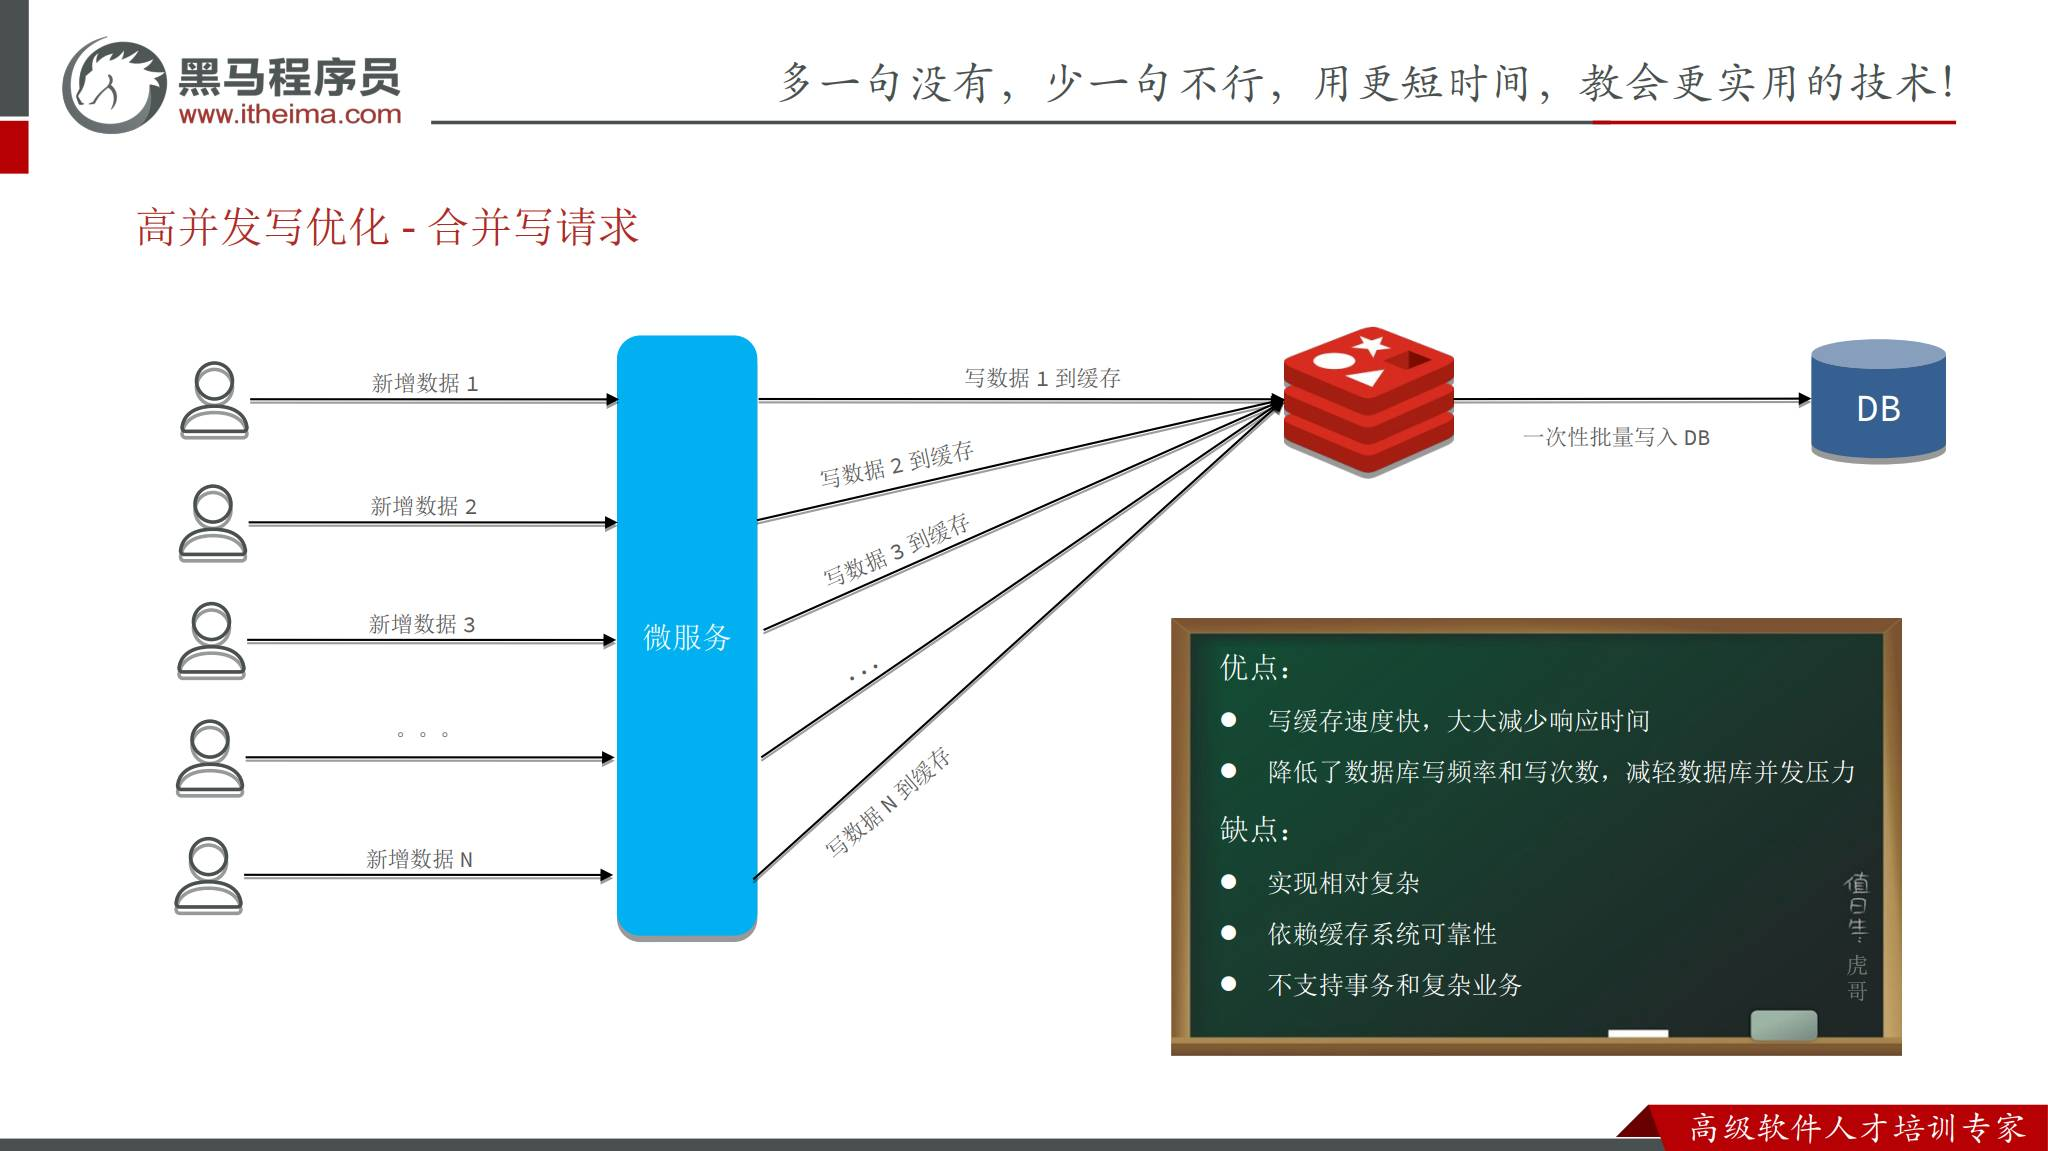

| 操作 | 是否减少业务记录数 | 是否减少往返开销 |
| --- | --- | --- |
| MQ 异步写 | 默认不减少 | 把数据库工作移出请求等待路径 |
| 批量写 | 保存的逻辑记录通常仍是 N 条 | 可以减少网络往返和提交开销 |
| 覆盖合并写 | 同一对象的 N 个状态只保留最后一个 | 同时减少有效更新次数 |

```text
同一小节：moment=10 → 25 → 40 → ... → 280
Redis：   每次覆盖旧 moment
MySQL：   条件满足后只保存最新的 moment=280
```

课程选择的是**同一小节的进度覆盖合并**。实际工具类仍逐条 `updateById`，并没有实现多条记录的一次 SQL 批量提交。

课件说该方案“不支持事务和复杂业务”，应理解为：**跨 Redis 和数据库的写回，不能直接获得一个普通数据库本地事务的原子性**。数据库内的多条 SQL 仍可使用事务；跨系统的一致性需要额外设计。


## 学习记录中的高频分支

提交接口同时处理考试、首次学习、首次完成和普通进度更新。优化全部流程会增加复杂度，应先找到最常出现的分支。

| 请求分支 | 频率与特点 | 课件的处理 |
| --- | --- | --- |
| 考试提交 | 课程场景中一次考试提交一次记录 | 立即插入已完成记录，更新完成小节数 |
| 视频记录不存在 | 同一用户的小节第一次记录 | 立即插入数据库，取得记录 id |
| 视频首次达到完成阈值 | 从未完成变成完成，业务事件只发生一次 | 立即更新完成状态、完成时间和课表计数，删除该小节缓存 |
| 普通视频进度 | 每 15 秒一次；包括已学完后继续观看 | 更新缓存，添加延迟任务，稍后落库 |

讲义用“95% 的请求”说明普通进度占多数，这是教学场景的估计，不是已取得的监控数据。

完成规则在文字中写“超过 50%”，实际代码是 `moment * 2 >= duration`，因此**达到 50% 即完成**。改进时可写 `2L * moment >= duration`，避免整数乘法溢出；视频时长应由服务端核实。


## 接口契约与优化边界

优化改变存储路径，调用方式保持课程定义：提交 `POST /learning-records`，查询 `GET /learning-records/course/{courseId}`。经过课程网关时，学习服务路径带 `/ls` 前缀。

| 提交字段 | 含义 | 本章用途 |
| --- | --- | --- |
| `lessonId` | 用户与课程关联的课表 id | Redis key、课表更新 |
| `sectionId` | 小节 id | Hash field、记录定位 |
| `sectionType` | 视频或考试 | 决定业务分支 |
| `moment` | 视频当前播放位置，单位秒 | 高频覆盖更新 |
| `duration` | 视频总时长，单位秒 | 判断完成阈值 |
| `commitTime` | 提交时间 | 课件用作首次完成时间 |

```json
{
  "lessonId": 1001,
  "sectionId": 2001,
  "sectionType": 1,
  "moment": 120,
  "duration": 600,
  "commitTime": "2026-10-09T10:00:00"
}
```

上述 `sectionType=1` 仅作为请求形状示例，实际数值按项目 `SectionType` 定义确定。

**补充**：登录用户从 `UserContext` 获取；还要校验课表归属、小节所属课程、有效学习资格，以及 `0 <= moment <= duration`。不能把客户端提交的 `lessonId` 当成访问授权。


## Redis Hash：一张课表聚合多个小节

只缓存播放位置仍需频繁查数据库判断记录是否存在、是否已完成。课件缓存 `id`、`moment`、`finished` 三个字段，同时减少读和写。

| 层级 | 课件设计 | 示例 |
| --- | --- | --- |
| Redis key | `learning:record:{lessonId}`，大括号表示格式占位符 | `learning:record:1001` |
| Hash field | `sectionId.toString()` | `2001` |
| Hash value | 记录的 JSON | `{"id":9001,"moment":120,"finished":false}` |

```text
learning:record:1001
├── 2001 → {id:9001, moment:120, finished:false}
├── 2002 → {id:9002, moment:242, finished:true}
└── 2003 → {id:9003, moment:20,  finished:false}
```

`lessonId` 表示一位用户的一张课表，天然区分不同用户。若仅用公共的 `courseId` 或 `sectionId` 作 key，多位用户的进度会互相覆盖。

| 缓存组织 | 优点 | 代价 |
| --- | --- | --- |
| 每个小节一个 key | 可独立设置 TTL | key 多，元数据开销较大 |
| 每张课表一个 Hash | key 较少，多个小节共用缓存生命周期 | Hash 整体续期，活跃小节会延长其他 field 的保留时间 |

PPT 的 `sectionId:01` 是示意标签；讲义代码直接使用小节 id 字符串作 field，不能按图中标签随意增加前缀。


## 缓存字段与延迟任务字段

缓存是当前状态，延迟任务是某次请求的快照。二者职责不同，没必要都保存整个数据库实体。

| 数据对象 | 课件字段 | 用途 |
| --- | --- | --- |
| `RecordCacheData` | `id`、`moment`、`finished` | 按 id 更新记录、判断完成状态、返回最新位置 |
| `RecordTaskData` | `lessonId`、`sectionId`、`moment` | 到期后找到缓存，并与本次提交位置比较 |

```java
// 课件结构简化，Lombok 负责生成 getter、setter 和无参构造
@Data
@NoArgsConstructor
class RecordCacheData {
    private Long id;
    private Integer moment;
    private Boolean finished;
}

@Data
@NoArgsConstructor
class RecordTaskData {
    private Long lessonId;
    private Long sectionId;
    private Integer moment;
}
```

课件将缓存 JSON 反序列化为 `LearningRecord`，其中没有 `lessonId`、`sectionId`、`userId`；这些值来自任务或当前请求。因此不能把缓存反序列化结果当作字段完整的 PO。

**补充**：要准确处理重试、乱序和最近学习时间，可增加 `version`、服务端接收时间 `receivedAt`、`dirty` 等字段。这里只说明扩展方向，后面的改进示例再解释它们的含义。


## TTL：缓存过期不等于数据已持久化

课件每次写入 Hash 后，把整个 key 的 TTL（存活时间）刷新为 **1 分钟**。缓存过期后，下次请求重新查询数据库并建立缓存。

```java
// 课件关键逻辑
String key = StringUtils.format("learning:record:{}", record.getLessonId());
String json = JsonUtils.toJsonStr(new RecordCacheData(record));
redisTemplate.opsForHash().put(key, record.getSectionId().toString(), json);
redisTemplate.expire(key, Duration.ofMinutes(1));
```

| 时间参数 | 课件值 | 作用 |
| --- | --- | --- |
| 前端提交周期 | 15 秒 | 定期报告播放位置 |
| 延迟检测时间 | 20 秒 | 等待下一次提交，判断旧快照是否仍有效 |
| 缓存 TTL | 60 秒 | 回收不活跃缓存 |

> `60 > 20` 只是正常情况下留出的余量。若任务积压、数据库失败或服务重启，缓存仍可能在落库之前过期。

**补充**：缓存兼任“未持久化数据缓冲区”时，不应只依赖短 TTL。待写数据需要可靠的任务索引、重试或持久消息；确认写回之后再按保留策略回收。`HSET` 与 `EXPIRE` 是两个命令，若需要原子地写入并续期，可以使用 Lua 脚本。


## 定时持久化与停止提交后的持久化

固定间隔扫描缓存很容易实现，但周期越短，写回越频繁；周期越长，数据库越容易落后。

| 方案 | 触发条件 | 优点 | 对本业务的不足 |
| --- | --- | --- | --- |
| 固定周期写回 | 每隔 T 秒执行 | 实现直观，易批量处理 | 连续播放时仍反复写入中间位置 |
| 延迟检测写回 | 某次提交后等待 20 秒，再比较缓存 | 持续播放时跳过旧快照，停止后保存最新位置 | 需要任务队列，不能仅凭它保证故障恢复 |

例如播放 15 分钟、每 15 秒提交一次，大约产生 60 次心跳。续播只需要最后的位置，没必要将每个中间位置都更新到数据库。

这种“等待一段安静时间，只执行最后一次”的思想叫**防抖（debounce）**。本章用每次提交一个延迟快照来实现近似防抖；任务数量并没有同步减少。

**补充**：若持续播放很久，单纯等待停止可能使数据库长时间落后。可以增加“最长未落库时间”，或让读取路径优先合并缓存，按业务需要选择。


## 20 秒延迟检测的时间线

每次普通进度提交，先覆盖 Redis，再创建一个包含当次 `moment` 的延迟任务。任务到期后比较快照与当前缓存：不同则退出，相同则持久化。

| 时间 | 事件 | Redis 当前值 | 延迟任务结果 |
| --- | --- | --- | --- |
| 0 秒 | 提交 `moment=120` | 120 | 创建 T1，20 秒后检查 |
| 15 秒 | 提交 `moment=135` | 135 | 创建 T2，35 秒后检查 |
| 20 秒 | T1 到期 | 135 | `120 != 135`，跳过 |
| 30 秒 | 提交 `moment=150` 后关闭页面 | 150 | 创建 T3，50 秒后检查 |
| 35 秒 | T2 到期 | 150 | `135 != 150`，跳过 |
| 50 秒 | T3 到期 | 150 | `150 == 150`，写回记录和课表最近学习信息 |

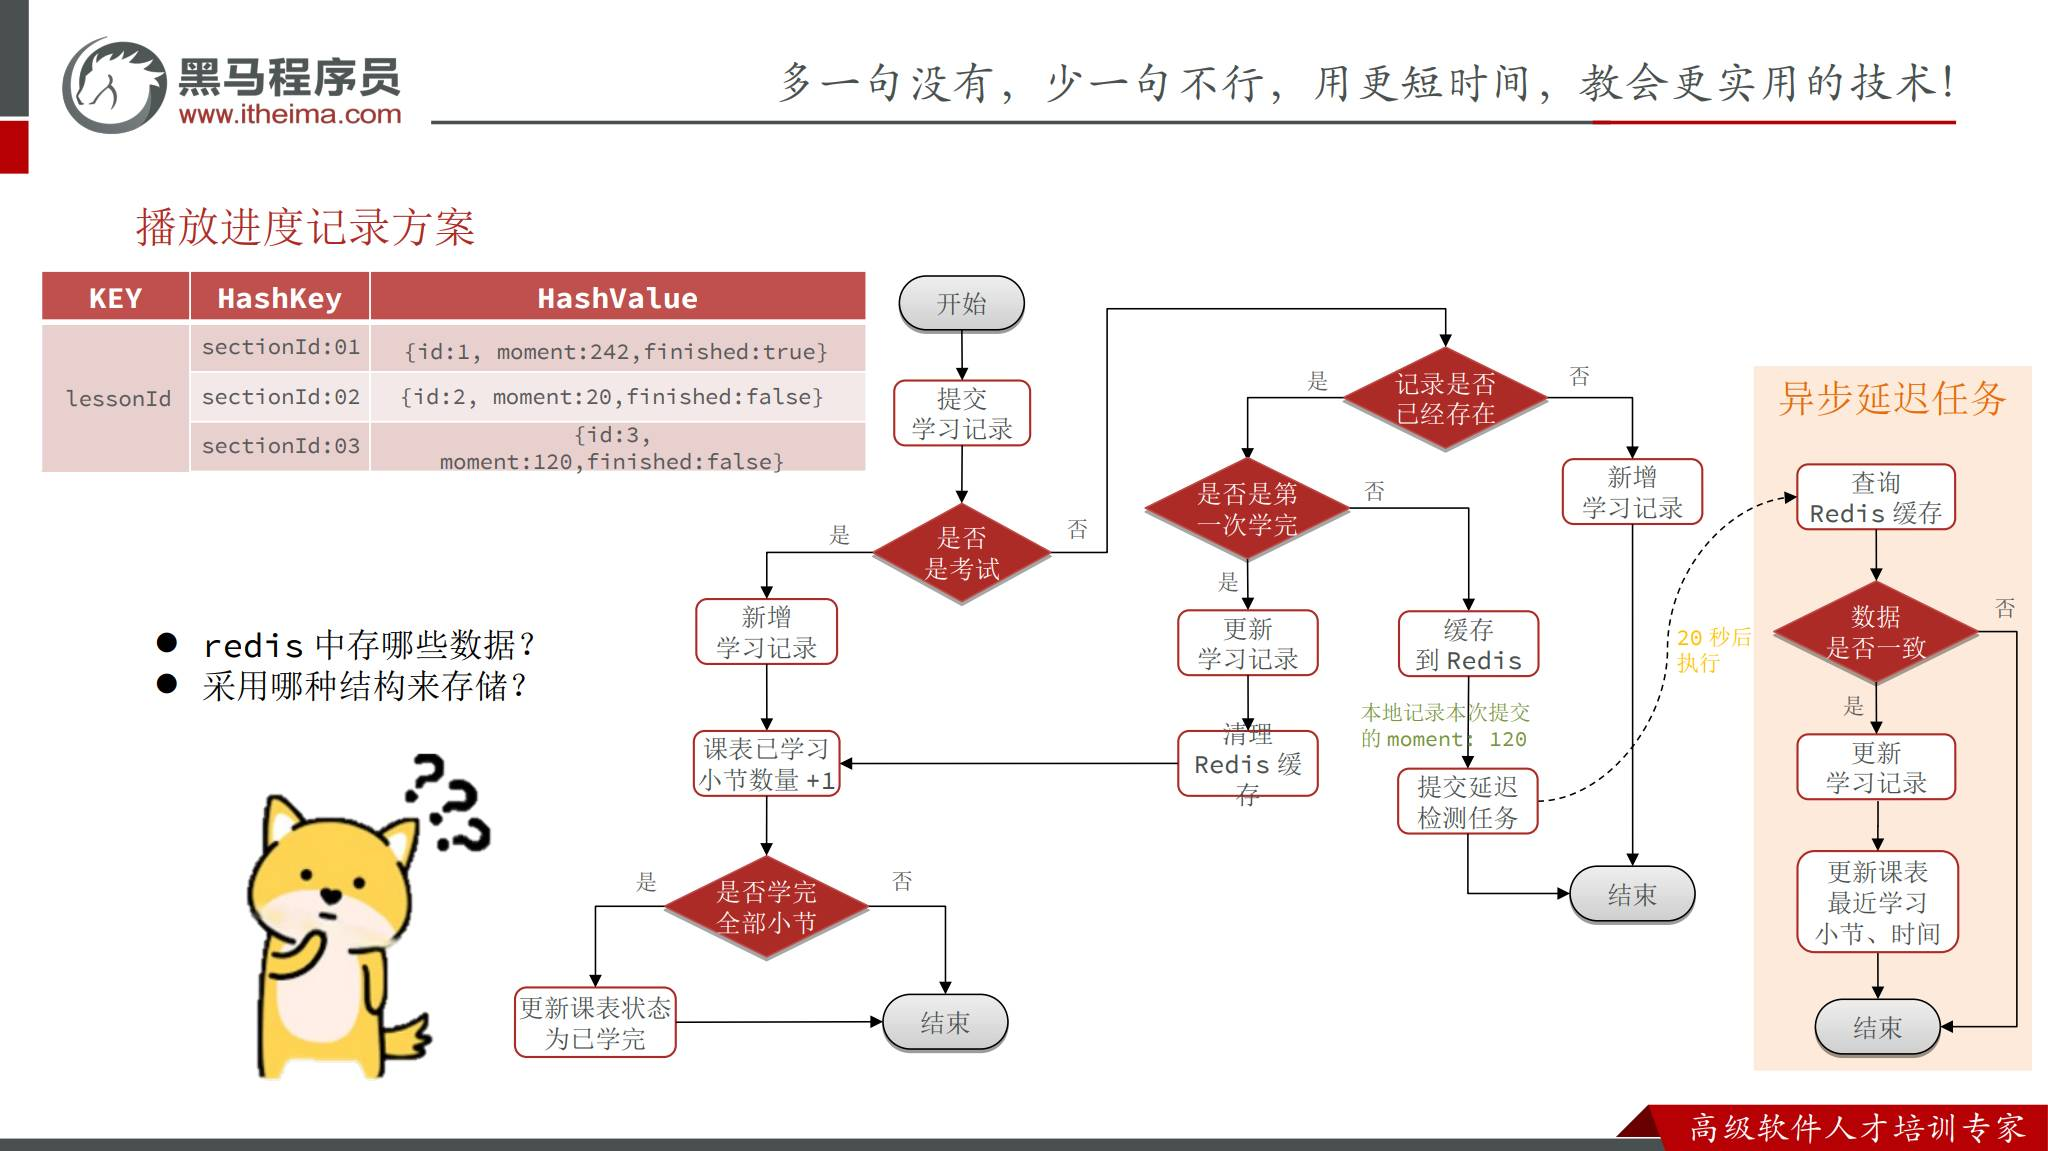

注意区分三个量：**播放位置误差、请求传输延迟、持久化延迟**。心跳每 15 秒一次，正常 1 倍速连续播放时最后报告的位置通常落后实际位置不超过约 15 秒；再等待 20 秒不会让已经报告的位置自动增加 20 秒。

> 课件“控制在 30 秒以内”的目标需要正常提交、任务及时执行和正确读取路径等前提。网络中断、倍速播放、快进或数据库只读旧值时，不能凭 `15 + 20` 两个参数就断言误差必然达标。


## 延迟任务的四种方案

延迟任务是“到达指定时间后才允许处理”的工作。它需要任务存储、到期排序和消费者；不等于为每个请求创建一个线程后 `sleep(20s)`。

| 方案 | 存储与实现 | 适合场景 | 主要边界 |
| --- | --- | --- | --- |
| JDK `DelayQueue` | JVM 内存中的阻塞优先队列 | 短延迟、允许自行补偿的本地任务 | 重启丢任务；单个队列不能跨 JVM 共享 |
| Redisson 延迟队列 | 通过 Redis 结构实现延迟投递 | 多实例共享任务 | 依赖 Redis 和客户端机制，仍需验证故障与消费语义 |
| MQ 延迟消息 | 原生延迟功能，或 TTL + 死信等机制 | 需要可靠投递、重试、跨实例消费 | 依赖消息系统；处理重复和积压 |
| 时间轮 | 用时间槽组织到期任务 | 大量本地计时任务 | 精度受时间槽影响；本地实现仍有重启丢失问题 |

PPT 提到 RocketMQ 的延迟消息和 RabbitMQ 插件；在线讲义举 RabbitMQ 死信队列。本质都是让消息稍后可消费。RabbitMQ 也可以用 TTL + 死信转发实现延迟，并非只能用插件。

课件选择 `DelayQueue`：不增加第三方服务交互，任务仅保留约 20 秒，教学成本低。这里“不依赖第三方”指任务队列本身，业务仍依赖 Redis。


## DelayQueue 的原理与方法

普通队列先入先出，延迟队列要先处理**最早到期**的任务。JDK 的 `DelayQueue<E extends Delayed>` 实现 `BlockingQueue`，内部使用 `PriorityQueue` 排序、`ReentrantLock` 协调并发。

| 方法或机制 | 含义 |
| --- | --- |
| `Delayed.getDelay(unit)` | 返回剩余等待时间；小于等于 0 表示到期 |
| `Delayed.compareTo(other)` | 定义任务的优先顺序，最早到期的排在前面 |
| `queue.add(task)` / `offer(task)` | 加入任务；队列是无界的，不靠容量限制阻塞生产者 |
| `queue.take()` | 取到期任务；为空或队首未到期时阻塞 |
| `queue.poll()` | 立即返回到期任务；没有则返回 null |
| `queue.poll(timeout, unit)` | 最多等待指定时间，期间有到期任务就返回 |

```java
public interface Delayed extends Comparable<Delayed> {
    long getDelay(TimeUnit unit);
}
```

`DelayQueue` 是任务容器，**不会自动运行任务里的业务代码**。应用必须安排消费者取出任务并执行。

**补充**：`take()` 的等待不是每个任务一个线程。消费者等队首到期；JDK 用条件等待等机制协调线程，未到期时不会一直忙循环查询时间。


## DelayTask：数据快照与单调时钟

任务需要保存业务数据和到期时间。课件使用 `System.nanoTime()` 计算期限，它适合度量经过的时间，不受系统日期校准直接影响；它不是可展示给用户的日期，也不能作为跨机器持久化时间戳。

下面是**改进示例**，保留课件的泛型任务结构，使用不可变字段和到期时间排序：

```java
import java.time.Duration;
import java.util.concurrent.Delayed;
import java.util.concurrent.TimeUnit;

public final class DelayTask<D> implements Delayed {
    private final D data;
    private final long deadlineNanos;

    public DelayTask(D data, Duration delay) {
        if (delay.isNegative()) {
            throw new IllegalArgumentException("delay 不能为负数");
        }
        this.data = data;
        this.deadlineNanos = System.nanoTime() + delay.toNanos();
    }

    public D getData() {
        return data;
    }

    @Override
    public long getDelay(TimeUnit unit) {
        return unit.convert(deadlineNanos - System.nanoTime(),
                            TimeUnit.NANOSECONDS);
    }

    @Override
    public int compareTo(Delayed other) {
        DelayTask<?> task = (DelayTask<?>) other;
        long diff = deadlineNanos - task.deadlineNanos;
        return diff < 0 ? -1 : (diff > 0 ? 1 : 0);
    }
}
```

该队列只放同一种 `DelayTask`；期限差在正常短延迟范围内。比较绝对期限的差，避免课件分别读取两个“剩余时间”造成采样时刻不同。课件还对剩余时间使用 `Math.max(0, ...)`，到期返回 0 也能被取出；保留负值更贴近接口语义。

`data` 也应是不可变快照，不能保存一个之后还会被请求线程修改的共享对象。跨服务调度则改用可持久化的时间戳，由统一时钟策略处理。


## DelayQueue 的最小用法

课件依次放入 3 秒、1 秒、2 秒的任务，用于观察它按到期顺序取出，而不是按插入顺序取出。

```java
DelayQueue<DelayTask<String>> queue = new DelayQueue<>();
queue.add(new DelayTask<>("任务3", Duration.ofSeconds(3)));
queue.add(new DelayTask<>("任务1", Duration.ofSeconds(1)));
queue.add(new DelayTask<>("任务2", Duration.ofSeconds(2)));

for (int i = 0; i < 3; i++) {
    DelayTask<String> task = queue.take();
    System.out.println(task.getData());
}
// 正常情况下依次得到：任务1、任务2、任务3
```

示例在同一个线程中等待，只用于理解 API。服务端应使用专用后台线程；请求线程只负责缓存和入队。

**反例**：为每次请求新建一个线程并休眠 20 秒，会让线程数量随请求增长；用共享公共线程池长期执行 `while(true) + take()`，又可能占住其他异步业务的执行资源。


## 延迟任务工具类的职责

如果服务类既负责考试、课程完成，又负责 Redis 和线程，代码会难以判断。课件拆出 `LearningRecordDelayTaskHandler`，将缓存与延迟任务集中管理。

| 方法 | 职责 | 调用位置 |
| --- | --- | --- |
| `writeRecordCache(record)` | 写缓存并刷新 TTL | 回源查询、普通进度提交 |
| `readRecordCache(lessonId, sectionId)` | 读取指定小节缓存 | 查询旧记录、任务检测 |
| `cleanRecordCache(lessonId, sectionId)` | 删除指定 Hash field | 首次学完后失效缓存 |
| `addLearningRecordTask(record)` | 写缓存并添加 20 秒延迟快照 | 普通进度分支 |
| `handleDelayTask()` | 消费到期任务，比较并持久化 | 后台线程 |

```java
// 课件字段与提交任务逻辑
private final StringRedisTemplate redisTemplate;
private final LearningRecordMapper recordMapper;
private final ILearningLessonService lessonService;
private final DelayQueue<DelayTask<RecordTaskData>> queue = new DelayQueue<>();

public void addLearningRecordTask(LearningRecord record) {
    writeRecordCache(record);
    queue.add(new DelayTask<>(new RecordTaskData(record),
                              Duration.ofSeconds(20)));
}
```

**补充**：缓存写失败应明确反馈或进入可靠的降级路径。课件 `writeRecordCache` 捕获异常后仅记录日志，调用方仍可能成功返回、继续入队；此时请求中的最新进度可能没有被可靠保存。


## 读缓存、回源与删除缓存

缓存命中时直接返回；未命中时按课表和小节查询数据库，再建立缓存。这样普通提交不会每次都读数据库。

```java
// 课件逻辑整理，增加 null 判断，避免把不存在的记录写入缓存
private LearningRecord queryOldRecord(Long lessonId, Long sectionId) {
    LearningRecord record = taskHandler.readRecordCache(lessonId, sectionId);
    if (record != null) {
        return record;
    }
    record = lambdaQuery()
        .eq(LearningRecord::getLessonId, lessonId)
        .eq(LearningRecord::getSectionId, sectionId)
        .one();
    if (record != null) { // 补充：原讲义这里直接调用 writeRecordCache(record)
        taskHandler.writeRecordCache(record);
    }
    return record;
}
```

```java
// 课件关键逻辑
String key = StringUtils.format("learning:record:{}", lessonId);
Object value = redisTemplate.opsForHash().get(key, sectionId.toString());
LearningRecord record = value == null ? null
    : JsonUtils.toBean(value.toString(), LearningRecord.class);

// 只删除这个小节，不删除其他小节的缓存
redisTemplate.opsForHash().delete(key, sectionId.toString());
```

课件读取失败也返回 null，调用方会回源数据库；这能继续读到已持久化数据，却无法恢复已经失败或丢失的未落库进度。缓存故障与正常未命中，至少应在日志和指标中区分。


## 普通视频更新与首次完成

服务入口中的 `finished` 返回值表示**本次是否新增了一个完成小节**，不是“这条记录当前是否完成”。已经完成的小节再次播放，应返回 false，避免重复增加计数。

```java
// 课件 handleVideoRecord 的核心分支，省略首次插入
LearningRecord old = queryOldRecord(dto.getLessonId(), dto.getSectionId());
boolean newlyFinished = !old.getFinished()
    && dto.getMoment() * 2 >= dto.getDuration();

if (!newlyFinished) {
    LearningRecord record = new LearningRecord();
    record.setId(old.getId());
    record.setLessonId(dto.getLessonId());
    record.setSectionId(dto.getSectionId());
    record.setMoment(dto.getMoment());
    record.setFinished(old.getFinished());
    taskHandler.addLearningRecordTask(record);
    return false;
}

boolean success = lambdaUpdate()
    .set(LearningRecord::getMoment, dto.getMoment())
    .set(LearningRecord::getFinished, true)
    .set(LearningRecord::getFinishTime, dto.getCommitTime())
    .eq(LearningRecord::getId, old.getId())
    .update();
if (!success) {
    throw new DbException("更新学习记录失败！");
}
taskHandler.cleanRecordCache(dto.getLessonId(), dto.getSectionId());
return true;
```

首次学完立即写数据库，是因为它会影响本周完成数、课表完成数和课程状态。这些不能仅靠后续普通进度覆盖保存。

**补充**：上面先读再判断的完成逻辑仍有并发窗口。首次完成的 SQL 应增加 `finished = false` 条件，以受影响行数判断本次是否完成状态转换，而不是仅凭缓存中的旧值。


## 首次插入、考试与课表计数

课件中，视频记录不存在时将 DTO 转成 PO、补 `userId` 并 `save(record)`，然后直接返回 false。考试分支则直接插入 `finished=true`、`finishTime=commitTime` 的记录，返回 true。

```java
// 课件提交入口的结构
@Transactional
public void addLearningRecord(LearningRecordFormDTO dto) {
    Long userId = UserContext.getUser();
    boolean newlyFinished = dto.getSectionType() == SectionType.VIDEO
        ? handleVideoRecord(userId, dto)
        : handleExamRecord(userId, dto);
    if (!newlyFinished) {
        return;
    }
    handleLearningLessonsChanges(dto);
}
```

课表处理查询课程总小节数，再执行 `learned_sections = learned_sections + 1`；第一次完成小节时将状态变为 `LEARNING`，全部完成时变为 `FINISHED`，设置课程完成时间。

| 课件实现的边界 | 补充处理 |
| --- | --- |
| 首次视频插入直接返回 false | 若首次提交已经达到阈值，应在创建时判定完成并计数 |
| 首次插入没有走延迟任务 | 最近学习小节和时间也应有明确更新路径 |
| 考试按“每章只能考一次”的业务假设直接插入 | 网络重试仍可能重复请求，需唯一约束与幂等处理 |
| 已学习数量用数据库表达式自增 | 仍需保证同一完成事件只触发一次 |
| `allLearned` 根据提前查到的数量判断 | 不同小节并发完成时，应避免以过期计数判断最终课程状态 |

**幂等**是重复处理相同请求不会产生额外业务效果。唯一索引只能防止重复记录，不能单独保证课表计数不会多加；应把“首次完成状态转换”和计数放在同一个数据库事务中。


## 延迟消费者：只更新进度，不覆盖完成状态

到期任务有三个结果：缓存不存在则退出；进度变化则退出；进度未变则写回两张表。

```java
// 课件 handleDelayTask 的核心逻辑，位于 while 循环中
DelayTask<RecordTaskData> task = queue.take();
RecordTaskData data = task.getData();
LearningRecord record = readRecordCache(data.getLessonId(), data.getSectionId());
if (record == null) {
    continue;
}
if (!Objects.equals(data.getMoment(), record.getMoment())) {
    continue;
}

record.setFinished(null);
recordMapper.updateById(record);

LearningLesson lesson = new LearningLesson();
lesson.setId(data.getLessonId());
lesson.setLatestSectionId(data.getSectionId());
lesson.setLatestLearnTime(LocalDateTime.now());
lessonService.updateById(lesson);
```

`finished=null` 的目的，是避免旧缓存把数据库里的 `true` 改回 `false`。它依赖 MyBatis-Plus 的字段更新策略忽略 null；不能只看 Java 代码就认定 SQL 一定不更新该列。

**改进示例**：显式限定要写的字段，意图更清楚。

```sql
UPDATE learning_record
SET moment = :moment
WHERE id = :recordId;
```

讲义的消费者**成功后没有删除缓存**，缓存继续保留到 TTL 到期。这里不能把“首次完成清理缓存”误写成“每次延迟落库后清理缓存”。反复相同的 `moment` 也可能触发多次相同更新。


## 最近学习时间与续播读取

写入变成延迟后，数据库在一段时间内落后于 Redis。查询如果仍只读数据库，就会漏掉最新位置。

课件 `queryLearningRecordByCourse` 查询课表，再查询 `learning_record`，直接封装返回，**没有合并 Redis 中尚未落库的进度**。用户关闭后立即换设备续播、或持续播放时另一设备打开，可能读到旧位置。

**补充读取策略**：先读数据库记录，再一次性读取该课表 Hash，将缓存中的 `moment` 覆盖到对应的小节；`finished`、`finishTime` 等完成事实保持数据库权威，避免旧缓存把已完成状态改回未完成。缓存不可用时按约定返回已持久化状态。

```text
查询数据库记录 ─┐
                ├→ 按 sectionId 合并 → 返回续播位置
批量读取 Redis ─┘       最新 moment 来自有效缓存
```

还要区分：

| 时间 | 含义 | 课件中的行为 |
| --- | --- | --- |
| `commitTime` | 请求携带的提交时间 | 首次完成记录使用它 |
| 服务端接收时间 | 服务端实际接到心跳的时间 | 课件任务未保存 |
| 任务执行时间 | 延迟消费者实际执行时间 | `latestLearnTime = LocalDateTime.now()` |

**补充**：最近学习时间宜保存经校验的事件时间或服务端接收时间。小节 A 的旧任务晚于小节 B 执行时，更新课表需比较时间或课表级版本，防止“最近小节”倒退。


## 播放秒数相等，不能严格证明停止提交

课件以 `moment` 不变推断停止播放，正常连续播放时容易理解，但暂停、重复请求、倒退拖动或多个设备都会破坏这个假设。

| 反例 | 仅比较 moment 的问题 |
| --- | --- |
| 播放器暂停后仍定期上报同一位置 | 请求还在来，但旧任务判断为停止，多次写库 |
| 位置从 120 → 135 → 120 | 旧任务与当前值相同，误把新状态当作自己的快照，称为 ABA 问题 |
| 相同请求重试 | 多个任务都满足相等条件，重复写回 |
| 任务比较后，新请求刚好到达 | 检查时是旧值，写入时已有更新；新进度必须由后续可靠路径保存 |

**改进示例**：给每次被接受的更新分配递增 `version`，快照保存相同版本。任务只有在“当前版本仍等于快照版本，且已达到安静时间”时才持久化。

```text
缓存：{id:9001, moment:120, finished:false, version:43, receivedAt:...}
任务：{lessonId:1001, sectionId:2001, version:43}

到期 → 当前版本为44：跳过
到期 → 当前版本仍为43：尝试写回版本43
```

版本表示更新顺序，不能简单用“更大的 moment”替代，因为用户允许回退播放。多设备之间仍需约定谁的更新生效；服务端接收顺序、会话版本等策略各有取舍。


## 数据库事务与缓存一致性

Redis、内存队列和 MySQL 是三个不同的状态系统。方法加上 `@Transactional`，只会覆盖它所配置的数据库事务，不会自动回滚 Redis，也不会持久化 DelayQueue。

| 位置 | 课件中的情况 | 补充改进 |
| --- | --- | --- |
| 首次完成 | 数据库更新后、事务提交前删除缓存 | 提交成功后失效缓存，配合重试；仍需考虑并发回填旧值 |
| 普通进度 | Redis 写入与本地入队是两个步骤 | 要能恢复“缓存写成功但尚未入队”这一窗口 |
| 延迟消费者 | 更新记录和课表，没有一个明确的共同事务 | 由独立的事务服务方法提交两张表 |
| 并发首次完成 | 先查旧值，再更新 | 条件更新，并以受影响行数决定是否计数 |

**改进示例：首次完成事务中的状态转换**。

```sql
UPDATE learning_record
SET finished = b'1', finish_time = :finishTime, moment = :moment
WHERE id = :recordId AND finished = b'0';
-- 只有受影响行数 = 1，才增加课表完成计数

UPDATE learning_lesson
SET learned_sections = learned_sections + 1
WHERE id = :lessonId;
```

如果需要据最新计数判断课程是否全部完成，可在同一事务中锁定课表行、更新后再判断，或设计等价的原子状态更新；同时检查唯一约束，避免两次首次插入。

> 同一类内部自调用带 `@Transactional` 的方法，可能绕过 Spring 代理。将写回操作放到独立 Spring Bean，由消费者调用，才能清楚建立事务边界。

本地事务保证两张表一起成功或一起回滚，但不能自动解决任务丢失、乱序写回或缓存回填竞争。


## 版本写回与条件清理

多个消费者可能乱序执行。旧任务先读取版本 43，随后版本 44 被持久化；如果版本 43 最后才写入，会把数据库进度改旧。

**补充方案**：数据库增加 `progress_version`，只允许较新版本更新。这里是设计示例，课件 DDL 没有该字段。

```sql
UPDATE learning_record
SET moment = :moment, progress_version = :version
WHERE id = :recordId AND progress_version < :version;
```

版本必须在该记录所有写路径上统一分配和使用，包括首次完成、普通进度、重试；单独给一个分支加版本仍可能被其他分支覆盖。课表的最近学习元数据也需要独立的排序规则。

若持久化后需要删除缓存或去掉 dirty 标记，必须确认缓存仍是已写入的版本，不能无条件 `HDEL`：

```text
读取 v43 → 写库 v43 → 新请求写缓存 v44 → 无条件删除
                                            ↑ 会误删 v44
```

可以通过 Lua 原子执行“当前版本等于 v43 才删除或标记干净”。**如果更新 SQL 返回 0，不能直接当作写回成功并清理缓存**：需要判断记录不存在、版本已经更高，还是其他前置条件不满足。


## 后台线程的启动与停止

课件在 `@PostConstruct` 中用 `CompletableFuture.runAsync(this::handleDelayTask)` 启动消费者，在 `@PreDestroy` 中将 `volatile begin` 设为 false。

`volatile` 能让其他线程看见标记变化，却不能唤醒已经阻塞在 `queue.take()` 的线程。也不宜让一个长期阻塞循环占用 `CompletableFuture` 默认的公共线程池。

下面是**改进示例**的生命周期骨架，`handleOne` 表示一次任务处理，应通过独立事务服务写回：

```java
private volatile boolean running;
private ExecutorService worker;

@PostConstruct
public void init() {
    running = true;
    worker = Executors.newSingleThreadExecutor();
    worker.submit(() -> {
        while (running && !Thread.currentThread().isInterrupted()) {
            try {
                DelayTask<RecordTaskData> task = queue.take();
                handleOne(task.getData());
            } catch (InterruptedException e) {
                Thread.currentThread().interrupt();
                break;
            } catch (Exception e) {
                log.error("延迟写回失败，需要重试或补偿", e);
                // 补充：把失败任务放入可靠重试路径，不能只记日志
            }
        }
    });
}

@PreDestroy
public void destroy() {
    running = false;
    worker.shutdownNow(); // 请求中断 take()，不保证所有业务立即停止
}
```

实际服务还应等待线程退出、明确正在处理任务的收尾策略，并有重启后补偿。Spring Boot 3 项目使用 `jakarta.annotation`；课程中的 `javax.annotation` 按其项目版本使用。


## 线程池练习与任务容量

讲义练习要求将单线程改为线程池，核心线程数与 CPU 核数一致。可以让多个专用消费者从同一个 DelayQueue 取任务；`take()` 能安全地把一个任务交给一个消费者。

```java
// 练习方向示例；后台池专用于这些长期运行的消费者
int workers = Runtime.getRuntime().availableProcessors();
ExecutorService pool = Executors.newFixedThreadPool(workers);
for (int i = 0; i < workers; i++) {
    pool.submit(this::consumeLoop);
}
```

`consumeLoop` 要正确处理中断与失败，停止时中断整个专用池。同一记录的不同任务仍可能分给不同消费者，必须用版本或串行化策略避免倒序写入。

| 需要判断的容量 | 估算与含义 |
| --- | --- |
| 入队速度 λ | 约等于普通进度请求 QPS |
| 正常待处理任务数 | 约 `λ × 延迟秒数`，还要加执行积压 |
| JVM 内存 | 每个任务及其对象引用的实际大小 × 任务数 |
| 数据库承载 | 消费者数受数据库连接池、SQL RT 和锁竞争限制 |

**示例假设**：3 万用户同时播放、每 15 秒提交一次，约 2000 请求/秒；20 秒窗口可有约 4 万个待检查任务，尚未计入积压。合并写减少数据库更新，却仍保留每次 Redis 读写和任务检查的成本。

**补充**：这些任务主要涉及 I/O 等待，CPU 核数只是练习起点。生产环境根据测量设消费者数量和容量上限；若采用“一个调度线程 + 有界工作池”，还要处理拒绝策略，不能把取出的任务静默丢掉。


## 重启、故障与多实例补偿

DelayQueue 放在 JVM 内存中，服务退出后任务消失。Redis 中保留的数据不会自动重新生成这些任务；等 TTL 到期，未落库进度也可能丢失。

| 故障或竞争 | 可能结果 | 补充措施 |
| --- | --- | --- |
| Redis 写失败但接口仍返回成功 | 最新进度没有可靠保存 | 明确失败、受控回退数据库或可靠消息路径 |
| 写缓存后、入队前宕机 | 有待写数据，没有任务 | 可恢复的 dirty 索引、周期补偿或持久任务 |
| 数据库失败，只记录异常 | 任务已取出，后续没有重试 | 重试、退避、失败告警，保留未确认状态 |
| 消费积压超过 TTL | 到期任务读不到数据 | 不让待写数据被无条件淘汰，监控积压 |
| 重启丢失 DelayQueue | 未持久化的进度缺少触发器 | 重建待写任务或采用 Redis/MQ 共享调度 |
| 多实例各有本地队列 | 同一课表任务分散、可能乱序 | 数据共享仍可工作，但需跨实例的版本、一致性和补偿设计 |

讲义称 DelayQueue“只能单机使用”，准确含义是**一个队列属于一个 JVM，不能作为多个实例共享的可靠任务存储**。多个服务实例可以各自使用它，Redis 数据仍共享，但本地任务丢失和并发竞争不会因此被解决。

引入持久化 MQ 或 Redis 调度也不能免除幂等与重试。要明确“成功返回”究竟代表已经持久化，还是进入了满足可靠性要求的待写缓冲区。


## 定时任务练习：扫描待写数据

讲义第二个练习是使用定时任务持久化。关键是找到**哪些数据还没写回**，而不是每次全量覆盖数据库。

**补充设计**：维护 dirty 集合或按到期时间排序的 ZSet。ZSet 是 Redis 的有序集合，可用 score 保存下一次允许写回的时间，以记录标识作为 member。

```text
心跳到达：更新缓存 + 更新该记录的版本、待写时间
定时任务：分批取得到期记录
          → 读取最新版本快照
          → 事务写回数据库
          → 版本仍相同才清理待写标记
          → 失败保留并安排重试
```

| 方案 | 适合情况 |
| --- | --- |
| 周期性写所有 dirty 数据 | 能容忍一个周期的数据库延迟，希望稳定批量写入 |
| 周期性扫描“安静 20 秒”的记录 | 希望保留停止后写回的语义，减少每次请求生成本地任务 |
| 安静时间 + 最大写回间隔 | 既减少中间更新，又限制连续播放时的数据库落后时间 |

课程可用 SpringTask 触发扫描。多实例部署时要分片或领取任务；不要让所有实例全量执行相同批次。缓存更新与待写标记最好原子完成，并配合失败重试，否则仍有“数据已更新却没有调度信息”的窗口。


## 验证方案与压测指标

性能优化必须同时证明“负载减少”和“业务正确”。共享目录有 `提交学习记录.jmx`，但本笔记未读取它的线程数、参数或断言，因此不把任何示例数值当作该脚本配置，也不声称获得了实测提升。

| 测试场景 | 应检查的结果 |
| --- | --- |
| 连续递增心跳 | 普通更新主要写缓存；旧快照跳过，停止后持久化最后位置 |
| 首次请求已达到 50% | 完成状态、完成时间、课表计数正确 |
| 阈值处重复提交、并发提交 | 同一小节只计数一次，finished 不回退 |
| 拖动进度、暂停后同值心跳 | 按定义更新位置，版本正确，不把相等位置当作相同事件 |
| 关闭后立即换设备读取 | 未落库的位置能通过缓存合并正确返回 |
| 同时切换多个小节 | 最近学习小节和时间不会被旧任务倒序覆盖 |
| Redis 故障、数据库失败、服务重启 | 请求结果符合约定，未完成写回能够补偿 |
| 大量任务与缓慢数据库 | 队列不无限失控，监控能发现延迟和过期风险 |

压测时使用同样的数据规模、并发和数据库环境比较优化前后；用户身份和课表应分散，避免只更新一个 id 的测试偏离真实场景。

| 指标 | 用来判断什么 |
| --- | --- |
| 请求 QPS、p95 / p99 RT、错误率 | 入口吞吐与长尾体验 |
| 每秒数据库查询、更新数、连接池等待 | 数据库负载是否确实降低 |
| Redis 命中率、命令耗时、内存 | 缓存是否成为新瓶颈 |
| 队列长度、最老任务等待时间、处理速率 | 消费是否积压 |
| 写回延迟、重试次数、dirty 数据年龄 | 最终持久化是否按时完成 |
| 续播位置误差、计数一致性 | 业务正确性是否被优化破坏 |


## 章节衔接与面试提示

本章仍围绕学习中心，下一章进入课程互动问答。讲义的预习任务是从产品原型梳理提问、回答及管理相关接口，并思考数据库实体；这属于 day05 的内容。

**面试提示**：介绍这个优化时，先讲约束，再讲为什么能合并，最后讲实现与故障边界。

> 为支持跨设备续播，我们把播放位置记录在服务端，前端每 15 秒上报一次。多数请求只更新同一小节的播放位置，中间位置不需要逐条保留，所以用课表级 Redis Hash 缓存最新状态。普通更新提交延迟检测任务，20 秒后发现没有新的有效更新才写回数据库；首次学完和考试完成立即处理，保证完成数统计。课程用 DelayQueue 演示任务调度，生产使用时还需要处理版本、幂等、缓存与数据库的一致性，以及重启恢复和失败重试。

| 常见追问 | 回答要点 |
| --- | --- |
| 为什么不只用 MQ？ | MQ 能移出等待路径、削峰；未经合并仍要执行全部更新 |
| 为什么能合并播放位置？ | 续播只需要最后位置，完成事件单独处理；支付流水不能这样覆盖 |
| 为什么等 20 秒？ | 大于正常 15 秒心跳周期，留出下一次更新的时间；不是故障环境下的严格保证 |
| DelayQueue 会自动执行吗？ | 不会，必须由消费者取到期任务并执行 |
| 进度相同就一定停止了吗？ | 不一定，暂停、重试和 ABA 需要版本及接收时间判断 |
| 已学完的状态会被旧任务覆盖吗？ | 普通写回只更新进度；首次完成用条件更新和事务保证计数 |
| 马上换设备如何读最新进度？ | 查询合并有效缓存；只读尚未更新的数据库会读旧位置 |
| 服务重启后怎么办？ | 本地任务会丢，需可恢复的待写索引、补偿扫描或持久任务系统 |

课程中的估算和原理示例不能替代实测。面试中应说明自己实际实现了哪部分、验证了哪些结果，不把补充方案或示意耗时当作已完成的项目成绩。
